# 城市接续边可视化与回流路径统计

- 写入日期：2026-10-17
- 修改日期：2026-10-21
- 本次内容：统计三年边权重、81城范围构成、直接回流占比，并整理直接回流路径明细。

本 Notebook 属于步骤01，读取现有三份年度城市接续数据，不修改原始轨迹和年度城市接续数据。

本次把“相邻下一站回到这台农机当年已经访问过的城市”记为一次**直接回流**。例如 `A-B-C-D-C-E` 中的 `D→C` 是一次直接回流，对应的完整回流片段是 `C-D-C`。这只是本次描述统计使用的简单定义，不代表后续研究的最终回流口径。
本次修改：核对并登记新候选接续版本，普通重跑取消自动归档；统计方法不变。


## 1 参数

这里设置输入、输出和是否允许覆盖。默认不覆盖已有结果。

In [1]:
from pathlib import Path
from datetime import datetime
import hashlib
import os
import shutil

import duckdb
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import FuncFormatter
import pandas as pd
from IPython.display import Markdown, display


def find_project_root(start_path):
    current_path = Path(start_path).resolve()
    for candidate_path in [current_path, *current_path.parents]:
        if (candidate_path / 'README.md').exists() and (candidate_path / 'Data').exists():
            return candidate_path
    raise FileNotFoundError('没有找到同时包含 README.md 和 Data 文件夹的项目根目录。')


project_root = find_project_root(Path.cwd())
analysis_years = [2021, 2022, 2023]
edge_files = {
    year: project_root / f'Data/03_有向边数据/{year}年农机城市接续.csv'
    for year in analysis_years
}
city_list_file = project_root / 'Data/02_筛选后81城数据/citys_2023_1.csv'
result_dir = project_root / 'Results/00_数据审计'
edge_data_dir = project_root / 'Data/03_有向边数据'

weight_table_file = result_dir / '边权重统计.csv'
city_scope_table_file = result_dir / '81城边范围统计.csv'
return_path_file = edge_data_dir / '回流路径.csv'
weight_chart_file = result_dir / '边权重数量.png'
city_scope_chart_file = result_dir / '81城边范围.png'
return_share_chart_file = result_dir / '直接回流占比.png'
output_files = [
    weight_table_file,
    city_scope_table_file,
    return_path_file,
    weight_chart_file,
    city_scope_chart_file,
    return_share_chart_file,
]

allow_overwrite = os.getenv('CITY_EDGE_ANALYSIS_ALLOW_OVERWRITE', '0') == '1'

for font_name in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS']:
    try:
        font_manager.findfont(font_name, fallback_to_default=False)
        plt.rcParams['font.sans-serif'] = [font_name]
        break
    except ValueError:
        continue
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

print(f'项目根目录：{project_root}')
print(f'允许覆盖已有结果：{allow_overwrite}')

项目根目录：C:\Users\Administrator\Desktop\W
允许覆盖已有结果：True


## 2 读取

读取三份年度城市接续数据和固定81城名单。81城按城市名称去掉首尾空格后精确匹配，不做模糊匹配。

In [2]:
required_edge_columns = {
    '年份', '农机编号', '链段编号', '起点访问序号', '终点访问序号',
    '起点城市', '终点城市', '边级', '跨越城市数', '衰减权重',
    '起点进入时间', '起点离开时间', '终点进入时间', '终点离开时间',
    '终点城市访问序次', '是否直接回流边', '来源文件'
}

missing_input_files = [str(path) for path in [*edge_files.values(), city_list_file] if not path.exists()]
if missing_input_files:
    raise FileNotFoundError(f'缺少输入文件：{missing_input_files}')

existing_output_files = [path for path in output_files if path.exists()]
if existing_output_files and not allow_overwrite:
    existing_names = '\n'.join(str(path) for path in existing_output_files)
    raise FileExistsError(
        '以下输出已经存在，Notebook 默认不覆盖：\n' + existing_names +
        '\n确认重跑时，请设置环境变量 CITY_EDGE_ANALYSIS_ALLOW_OVERWRITE=1。'
    )

# 修改前统一归档；普通重跑不再自动复制旧结果。

for output_dir in [result_dir, edge_data_dir]:
    output_dir.mkdir(parents=True, exist_ok=True)

manifest_path = project_root / 'Data/data_manifest.csv'
manifest_table = pd.read_csv(manifest_path,encoding='utf-8-sig',dtype='string',keep_default_na=False)
for year,path in edge_files.items():
    relative = path.relative_to(project_root).as_posix()
    entry = manifest_table.loc[manifest_table['relative_path'].eq(relative)]
    assert len(entry)==1 and entry.iloc[0]['formal_status']=='正式'
    with path.open('rb') as handle:
        digest = hashlib.file_digest(handle,'sha256').hexdigest()
    assert digest==entry.iloc[0]['sha256'] and path.stat().st_size==int(entry.iloc[0]['file_size_bytes'])
connection = duckdb.connect()
edge_select_sql = []
for year, file_path in edge_files.items():
    escaped_path = file_path.as_posix().replace("'", "''")
    edge_select_sql.append(f"SELECT * FROM read_csv_auto('{escaped_path}', header=true)")
connection.execute('CREATE OR REPLACE TEMP VIEW all_edges AS ' + ' UNION ALL '.join(edge_select_sql))

actual_columns = {row[0] for row in connection.execute('DESCRIBE all_edges').fetchall()}
missing_columns = sorted(required_edge_columns - actual_columns)
if missing_columns:
    raise ValueError(f'年度城市接续数据缺少字段：{missing_columns}')

city_list = pd.read_csv(city_list_file, encoding='utf-8-sig', dtype='string')
if 'city' not in city_list.columns:
    raise ValueError('81城名单缺少 city 字段。')
city_list['city'] = city_list['city'].str.strip()
if len(city_list) != 81 or city_list['city'].nunique(dropna=True) != 81 or city_list['city'].isna().any():
    raise ValueError('81城名单不是81个互不重复且非空的城市，程序停止。')

connection.register('city_list_dataframe', city_list[['city']])
connection.execute('CREATE OR REPLACE TEMP TABLE city_list AS SELECT DISTINCT city FROM city_list_dataframe')

input_check = connection.execute(
    '''
    SELECT
        "年份" AS year,
        COUNT(*) AS edge_count,
        COUNT(DISTINCT "农机编号") AS machine_count,
        SUM(CASE WHEN "起点城市" IS NULL OR trim("起点城市") = ''
                      OR "终点城市" IS NULL OR trim("终点城市") = ''
                 THEN 1 ELSE 0 END) AS missing_city_count
    FROM all_edges
    GROUP BY 1
    ORDER BY 1
    '''
).fetchdf()

if input_check['year'].astype(int).tolist() != analysis_years:
    raise ValueError('输入年份不是2021、2022、2023。')
if input_check['missing_city_count'].sum() != 0:
    raise ValueError('年度城市接续数据中仍有起点或终点城市为空的记录。')
display(input_check.rename(columns={
    'year': '年份', 'edge_count': '边数量', 'machine_count': '农机数量',
    'missing_city_count': '城市空值数量'
}))

,年份,边数量,农机数量,城市空值数量
0,2021,110458,11246,0.0
1,2022,274939,29249,0.0
2,2023,500068,41201,0.0


## 3 处理

先统计权重和81城范围，再从一级边还原城市访问顺序，整理直接回流路径。

In [3]:
weight_stats = connection.execute(
    '''
    SELECT
        CAST("年份" AS INTEGER) AS year,
        CAST("边级" AS INTEGER) AS edge_level,
        CAST("跨越城市数" AS INTEGER) AS skipped_visit_count,
        CAST("衰减权重" AS DOUBLE) AS edge_weight,
        COUNT(*) AS edge_count
    FROM all_edges
    GROUP BY 1, 2, 3, 4
    ORDER BY 1, 2
    '''
).fetchdf()
weight_stats['year_share'] = weight_stats['edge_count'] / weight_stats.groupby('year')['edge_count'].transform('sum')

city_scope_stats = connection.execute(
    '''
    SELECT
        CAST(e."年份" AS INTEGER) AS year,
        CASE
            WHEN source_city.city IS NOT NULL AND target_city.city IS NOT NULL THEN '两端都在81城'
            WHEN source_city.city IS NULL AND target_city.city IS NULL THEN '两端都不在81城'
            ELSE '一端不在81城'
        END AS city_scope_type,
        COUNT(*) AS edge_count
    FROM all_edges AS e
    LEFT JOIN city_list AS source_city ON trim(e."起点城市") = source_city.city
    LEFT JOIN city_list AS target_city ON trim(e."终点城市") = target_city.city
    GROUP BY 1, 2
    ORDER BY
        1,
        CASE city_scope_type
            WHEN '两端都在81城' THEN 1
            WHEN '一端不在81城' THEN 2
            ELSE 3
        END
    '''
).fetchdf()

In [4]:
city_scope_stats['year_share'] = city_scope_stats['edge_count'] / city_scope_stats.groupby('year')['edge_count'].transform('sum')

connection.execute(
    '''
    CREATE OR REPLACE TEMP TABLE direct_edges AS
    SELECT
        CAST("年份" AS INTEGER) AS year,
        CAST("农机编号" AS VARCHAR) AS did,
        CAST("链段编号" AS INTEGER) AS chain_segment,
        CAST("起点访问序号" AS INTEGER) AS source_visit_order,
        CAST("终点访问序号" AS INTEGER) AS target_visit_order,
        CAST("起点城市" AS VARCHAR) AS source_city,
        CAST("终点城市" AS VARCHAR) AS target_city,
        CAST("起点进入时间" AS TIMESTAMP) AS source_entry_time,
        CAST("起点离开时间" AS TIMESTAMP) AS source_exit_time,
        CAST("终点进入时间" AS TIMESTAMP) AS target_entry_time,
        CAST("终点离开时间" AS TIMESTAMP) AS target_exit_time,
        CAST("终点城市访问序次" AS INTEGER) AS target_city_visit_no,
        CAST("是否直接回流边" AS BOOLEAN) AS is_direct_return_edge,
        CAST("来源文件" AS VARCHAR) AS source_file
    FROM all_edges
    WHERE CAST("边级" AS INTEGER) = 1
    '''
)

connection.execute(
    '''
    CREATE OR REPLACE TEMP TABLE visit_candidates AS
    SELECT
        year, did, chain_segment, source_visit_order AS visit_order,
        source_city AS city, source_entry_time AS entry_time, source_exit_time AS exit_time, source_file
    FROM direct_edges
    UNION ALL
    SELECT
        year, did, chain_segment, target_visit_order AS visit_order,
        target_city AS city, target_entry_time AS entry_time, target_exit_time AS exit_time, source_file
    FROM direct_edges
    '''
)

visit_conflict_count = connection.execute(
    '''
    SELECT COUNT(*)
    FROM (
        SELECT year, did, chain_segment, visit_order
        FROM visit_candidates
        GROUP BY 1, 2, 3, 4
        HAVING COUNT(DISTINCT city) > 1
            OR COUNT(DISTINCT entry_time) > 1
            OR COUNT(DISTINCT exit_time) > 1
    )
    '''
).fetchone()[0]
if visit_conflict_count != 0:
    raise ValueError(f'同一个访问序号出现了互相冲突的城市或时间，共{visit_conflict_count}组。')

connection.execute(
    '''
    CREATE OR REPLACE TEMP TABLE visits AS
    SELECT
        year, did, chain_segment, visit_order,
        min(city) AS city, min(entry_time) AS entry_time, min(exit_time) AS exit_time, min(source_file) AS source_file
    FROM visit_candidates
    GROUP BY 1, 2, 3, 4
    '''
)

return_path_data = connection.execute(
    '''
    WITH ordered_visits AS (
        SELECT
            *,
            ROW_NUMBER() OVER (
                PARTITION BY year, did, chain_segment, city
                ORDER BY visit_order
            ) AS city_visit_no,
            LAG(visit_order) OVER (
                PARTITION BY year, did, chain_segment, city
                ORDER BY visit_order
            ) AS previous_same_city_visit_order
        FROM visits
    ),
    return_base AS (
        SELECT
            current_visit.year,
            current_visit.did,
            current_visit.chain_segment,
            current_visit.previous_same_city_visit_order,
            current_visit.visit_order AS return_visit_order,
            current_visit.city AS return_city,
            direct_edge.source_city AS pre_return_city,
            previous_visit.entry_time AS previous_entry_time,
            previous_visit.exit_time AS previous_exit_time,
            current_visit.entry_time AS return_entry_time,
            current_visit.exit_time AS return_exit_time,
            date_diff('second', previous_visit.exit_time, current_visit.entry_time) / 3600.0 AS return_gap_hours,
            current_visit.city_visit_no AS return_city_visit_no,
            current_visit.source_file
        FROM ordered_visits AS current_visit
        INNER JOIN visits AS previous_visit
            ON current_visit.year = previous_visit.year
           AND current_visit.did = previous_visit.did
           AND current_visit.chain_segment = previous_visit.chain_segment
           AND current_visit.previous_same_city_visit_order = previous_visit.visit_order
        INNER JOIN direct_edges AS direct_edge
            ON current_visit.year = direct_edge.year
           AND current_visit.did = direct_edge.did
           AND current_visit.chain_segment = direct_edge.chain_segment
           AND current_visit.visit_order = direct_edge.target_visit_order
        WHERE current_visit.previous_same_city_visit_order IS NOT NULL
    ),
    return_paths_raw AS (
        SELECT
            return_base.*,
            string_agg(path_visit.city, '→' ORDER BY path_visit.visit_order) AS return_path,
            return_base.return_visit_order - return_base.previous_same_city_visit_order AS return_span_visits,
            return_base.return_visit_order - return_base.previous_same_city_visit_order - 1 AS intermediate_visit_count,
            COUNT(DISTINCT CASE
                WHEN path_visit.visit_order > return_base.previous_same_city_visit_order
                 AND path_visit.visit_order < return_base.return_visit_order
                THEN path_visit.city END
            ) AS intermediate_unique_city_count
        FROM return_base
        INNER JOIN visits AS path_visit
            ON return_base.year = path_visit.year
           AND return_base.did = path_visit.did
           AND return_base.chain_segment = path_visit.chain_segment
           AND path_visit.visit_order BETWEEN return_base.previous_same_city_visit_order AND return_base.return_visit_order
        GROUP BY ALL
    ),
    numbered_returns AS (
        SELECT
            *,
            ROW_NUMBER() OVER (
                PARTITION BY year, did, chain_segment
                ORDER BY return_visit_order
            ) AS machine_year_return_no
        FROM return_paths_raw
    )
    SELECT
        CAST(year AS VARCHAR) || '-' || did || '-' || CAST(chain_segment AS VARCHAR)
            || '-R' || lpad(CAST(machine_year_return_no AS VARCHAR), 3, '0') AS return_id,
        year, did, chain_segment, machine_year_return_no,
        previous_same_city_visit_order, return_visit_order, return_city, pre_return_city, return_path,
        return_span_visits, intermediate_visit_count, intermediate_unique_city_count,
        previous_entry_time, previous_exit_time, return_entry_time, return_exit_time, return_gap_hours,
        return_city_visit_no, return_gap_hours < 0 AS has_return_time_conflict,
        return_city_list.city IS NOT NULL AS return_city_in_81,
        pre_return_city_list.city IS NOT NULL AS pre_return_city_in_81,
        COUNT(*) OVER (PARTITION BY year, return_path) AS same_year_path_count,
        COUNT(*) OVER (PARTITION BY return_path) AS all_years_path_count,
        source_file
    FROM numbered_returns
    LEFT JOIN city_list AS return_city_list ON return_city = return_city_list.city
    LEFT JOIN city_list AS pre_return_city_list ON pre_return_city = pre_return_city_list.city
    ORDER BY year, did, chain_segment, return_visit_order
    '''
).fetchdf()

## 4 检查

核对数量、权重公式、81城分类合计和回流路径。任何一项不一致都会停止。

In [5]:
edge_totals = input_check.set_index('year')['edge_count'].astype(int).sort_index()
weight_totals = weight_stats.groupby('year')['edge_count'].sum().astype(int).sort_index()
city_scope_totals = city_scope_stats.groupby('year')['edge_count'].sum().astype(int).sort_index()
assert edge_totals.equals(weight_totals), '边权重统计合计与输入边数不一致。'
assert edge_totals.equals(city_scope_totals), '81城范围统计合计与输入边数不一致。'

weight_error = (weight_stats['edge_weight'] - 0.5 ** (weight_stats['edge_level'] - 1)).abs().max()
assert weight_error < 1e-12, '边权重与0.5^(边级-1)不一致。'
assert (weight_stats['skipped_visit_count'] == weight_stats['edge_level'] - 1).all(), '跨越城市数与边级不一致。'

direct_return_check = connection.execute(
    '''
    SELECT
        year,
        COUNT(*) AS direct_edge_count,
        SUM(CASE WHEN is_direct_return_edge THEN 1 ELSE 0 END) AS marked_return_count
    FROM direct_edges
    GROUP BY 1
    ORDER BY 1
    '''
).fetchdf()
return_dataset_counts = return_path_data.groupby('year').size().rename('return_dataset_count').reset_index()
direct_return_check = direct_return_check.merge(return_dataset_counts, on='year', how='left')
assert (direct_return_check['marked_return_count'] == direct_return_check['return_dataset_count']).all(), '回流路径行数与原接续数据标记不一致。'
assert not return_path_data['return_id'].duplicated().any(), '回流记录编号重复。'
assert (return_path_data['return_span_visits'] >= 2).all(), '发现相邻同城，和连续同城已合并的规则冲突。'
assert return_path_data['return_path'].str.split('→').str[0].eq(return_path_data['return_city']).all(), '回流路径起点不是回流城市。'
assert return_path_data['return_path'].str.split('→').str[-1].eq(return_path_data['return_city']).all(), '回流路径终点不是回流城市。'

return_summary = connection.execute(
    '''
    SELECT
        year,
        COUNT(*) AS direct_edge_count,
        SUM(CASE WHEN is_direct_return_edge THEN 1 ELSE 0 END) AS return_event_count,
        COUNT(DISTINCT did) FILTER (WHERE is_direct_return_edge) AS return_machine_count,
        SUM(CASE WHEN is_direct_return_edge THEN 1 ELSE 0 END)::DOUBLE / COUNT(*) AS return_share
    FROM direct_edges
    GROUP BY 1
    ORDER BY 1
    '''
).fetchdf()
unique_path_counts = return_path_data.groupby('year')['return_path'].nunique().rename('unique_return_path_count').reset_index()
return_summary = return_summary.merge(unique_path_counts, on='year', how='left')
display(return_summary.rename(columns={
    'year': '年份', 'direct_edge_count': '一级边数量', 'return_event_count': '直接回流次数',
    'return_machine_count': '发生直接回流的农机数', 'return_share': '直接回流占一级边比例',
    'unique_return_path_count': '不同回流路径数'
}).style.format({'直接回流占一级边比例': '{:.2%}'}).hide(axis='index'))

年份,一级边数量,直接回流次数,发生直接回流的农机数,直接回流占一级边比例,不同回流路径数
2021,37243,5714.000000,3181,15.34%,1136
2022,93416,16660.000000,8022,17.83%,1525
2023,153712,28853.000000,13991,18.77%,3064


## 5 输出

输出两张统计表、三张图片和一份回流路径明细。CSV统一使用UTF-8-SIG编码。

In [6]:
weight_output = weight_stats.rename(columns={
    'year': '年份',
    'edge_level': '边级',
    'skipped_visit_count': '跨越城市数',
    'edge_weight': '衰减权重',
    'edge_count': '边数量',
    'year_share': '占本年全部边比例',
})
city_scope_output = city_scope_stats.rename(columns={
    'year': '年份',
    'city_scope_type': '81城范围类型',
    'edge_count': '边数量',
    'year_share': '占本年全部边比例',
})
return_output = return_path_data.rename(columns={
    'return_id': '回流记录编号',
    'year': '年份',
    'did': '农机编号',
    'chain_segment': '链段编号',
    'machine_year_return_no': '本机年度回流序次',
    'previous_same_city_visit_order': '上次到达该城访问序号',
    'return_visit_order': '本次返回该城访问序号',
    'return_city': '回流城市',
    'pre_return_city': '回流前城市',
    'return_path': '回流路径',
    'return_span_visits': '回流跨度访问数',
    'intermediate_visit_count': '中间经过访问数',
    'intermediate_unique_city_count': '中间经过不同城市数',
    'previous_entry_time': '上次进入该城时间',
    'previous_exit_time': '上次离开该城时间',
    'return_entry_time': '本次返回进入时间',
    'return_exit_time': '本次返回离开时间',
    'return_gap_hours': '离开后返回间隔小时',
    'return_city_visit_no': '回流城市访问序次',
    'has_return_time_conflict': '是否时间冲突',
    'return_city_in_81': '回流城市是否81城',
    'pre_return_city_in_81': '回流前城市是否81城',
    'same_year_path_count': '同年同路径出现次数',
    'all_years_path_count': '三年同路径出现次数',
    'source_file': '来源文件',
})

weight_output.to_csv(weight_table_file, index=False, encoding='utf-8-sig')
city_scope_output.to_csv(city_scope_table_file, index=False, encoding='utf-8-sig')
return_output.to_csv(
    return_path_file, index=False, encoding='utf-8-sig', date_format='%Y-%m-%d %H:%M:%S'
)
print('CSV已输出。')

CSV已输出。


### 图1 不同权重的边数量

- 数据范围：2021、2022、2023年全部城市接续边，共三份年度数据。
- 横轴：边级。一级边权重为1，N级边权重为 `0.5^(N-1)`；准确权重见下方表格。
- 纵轴：边数量，单位为条。因为高等级边数量比一级边少很多，纵轴使用对数刻度，避免尾部看不清。
- 分组：颜色表示年份。折线只用于连接有顺序的边级，不表示时间趋势。

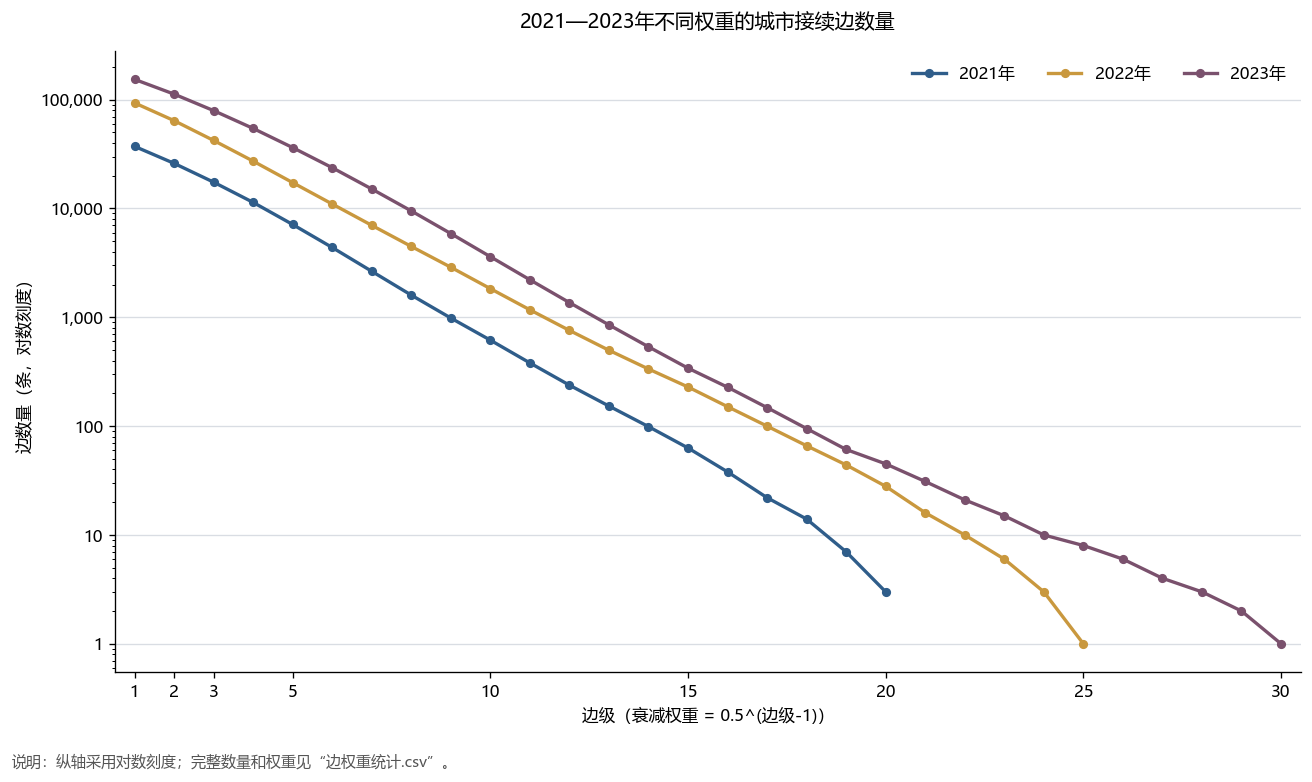

In [7]:
year_colors = {2021: '#2F5D8A', 2022: '#C9983E', 2023: '#7A516D'}
fig, axis = plt.subplots(figsize=(11, 6.5))
for year in analysis_years:
    year_data = weight_stats[weight_stats['year'] == year]
    axis.plot(
        year_data['edge_level'], year_data['edge_count'],
        marker='o', markersize=4.5, linewidth=2.0,
        color=year_colors[year], label=f'{year}年'
    )
axis.set_yscale('log')
axis.set_xlim(0.5, weight_stats['edge_level'].max() + 0.5)
axis.set_xticks([1, 2, 3, 5, 10, 15, 20, 25, 30])
axis.set_xlabel('边级（衰减权重 = 0.5^(边级-1)）')
axis.set_ylabel('边数量（条，对数刻度）')
axis.set_title('2021—2023年不同权重的城市接续边数量', pad=14)
axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{int(value):,}' if value >= 1 else f'{value:g}'))
axis.grid(axis='y', which='major', color='#D9DDE3', linewidth=0.8)
axis.spines[['top', 'right']].set_visible(False)
axis.legend(frameon=False, ncol=3, loc='upper right')
fig.text(0.01, 0.01, '说明：纵轴采用对数刻度；完整数量和权重见“边权重统计.csv”。', fontsize=9, color='#555555')
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(weight_chart_file, dpi=180, bbox_inches='tight', facecolor='white')
plt.show()

In [8]:
weight_count_table = (
    weight_stats.pivot(index=['edge_level', 'edge_weight'], columns='year', values='edge_count')
    .fillna(0)
    .astype(int)
    .reset_index()
    .rename(columns={'edge_level': '边级', 'edge_weight': '衰减权重', 2021: '2021年', 2022: '2022年', 2023: '2023年'})
)
display(weight_count_table.style.format({
    '衰减权重': '{:.10g}', '2021年': '{:,}', '2022年': '{:,}', '2023年': '{:,}'
}).hide(axis='index'))

边级,衰减权重,2021年,2022年,2023年
1,1,"37,243","93,416","153,712"
2,0.5,"25,997","64,167","112,511"
3,0.25,"17,461","42,202","79,333"
4,0.125,"11,377","27,243","54,439"
5,0.0625,"7,130","17,293","36,279"
6,0.03125,"4,382","10,996","23,707"
7,0.015625,"2,648","7,004","15,111"
8,0.0078125,"1,600","4,481","9,498"
9,0.00390625,985,"2,885","5,885"
10,0.001953125,617,"1,835","3,607"


### 图2 边的两端是否属于81城

- 数据范围：2021、2022、2023年全部城市接续边。
- 横轴：年份。
- 纵轴：边数量，单位为条。
- 分组：两端都在81城、一端不在81城、两端都不在81城。
- 图内同时标出数量和占本年全部边的比例。这里按城市名称精确匹配固定81城名单。

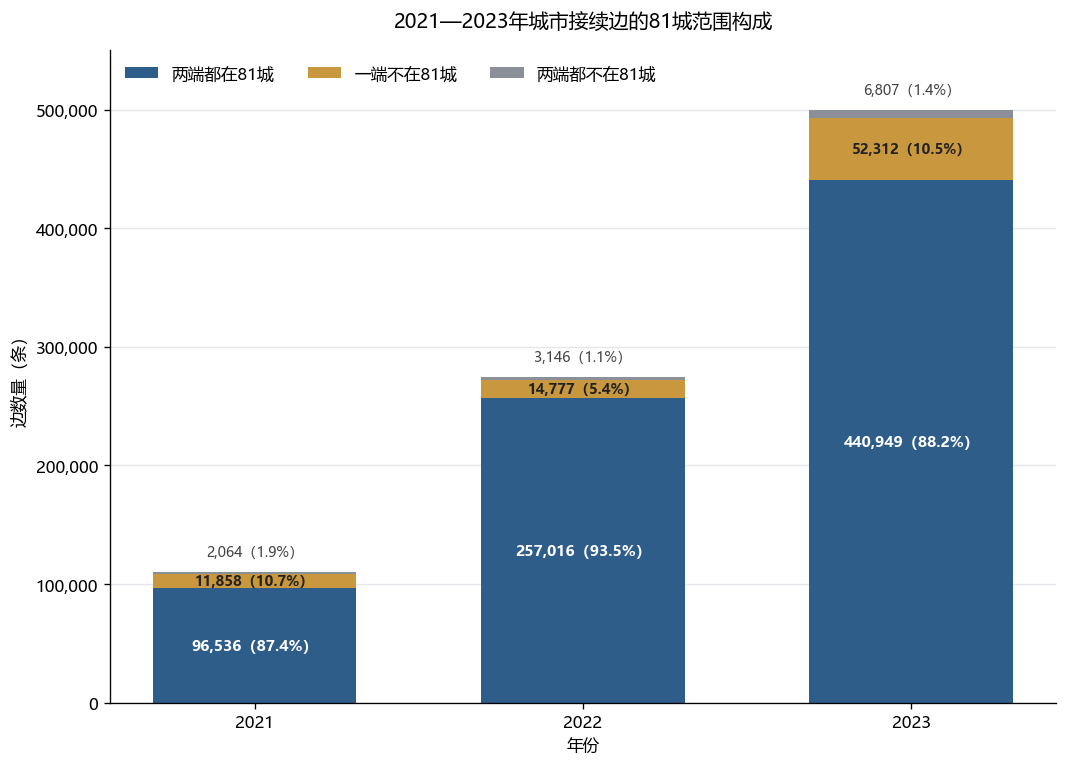

In [9]:
scope_order = ['两端都在81城', '一端不在81城', '两端都不在81城']
scope_colors = {
    '两端都在81城': '#2F5D8A',
    '一端不在81城': '#C9983E',
    '两端都不在81城': '#8A8F98',
}
count_pivot = city_scope_stats.pivot(index='year', columns='city_scope_type', values='edge_count').reindex(columns=scope_order)
share_pivot = city_scope_stats.pivot(index='year', columns='city_scope_type', values='year_share').reindex(columns=scope_order)

fig, axis = plt.subplots(figsize=(9, 6.5))
bottom_values = pd.Series(0.0, index=count_pivot.index)
for scope_type in scope_order:
    bars = axis.bar(
        count_pivot.index.astype(str), count_pivot[scope_type], bottom=bottom_values,
        color=scope_colors[scope_type], label=scope_type, width=0.62
    )
    for bar_index, bar in enumerate(bars):
        count_value = int(count_pivot.iloc[bar_index][scope_type])
        share_value = float(share_pivot.iloc[bar_index][scope_type])
        bar_center = bar.get_x() + bar.get_width() / 2
        if scope_type == '两端都在81城':
            axis.text(
                bar_center, bottom_values.iloc[bar_index] + count_value / 2,
                f'{count_value:,}（{share_value:.1%}）',
                ha='center', va='center', fontsize=9,
                color='white', fontweight='bold'
            )
        elif scope_type == '一端不在81城':
            axis.text(
                bar_center, bottom_values.iloc[bar_index] + count_value / 2,
                f'{count_value:,}（{share_value:.1%}）',
                ha='center', va='center', fontsize=8.5,
                color='#222222', fontweight='bold'
            )
        else:
            total_height = bottom_values.iloc[bar_index] + count_value
            axis.annotate(
                f'{count_value:,}（{share_value:.1%}）',
                xy=(bar_center, total_height),
                xytext=(0, 7), textcoords='offset points',
                ha='center', va='bottom', fontsize=8.5, color='#444444'
            )
    bottom_values = bottom_values + count_pivot[scope_type]

axis.set_xlabel('年份')
axis.set_ylabel('边数量（条）')
axis.set_title('2021—2023年城市接续边的81城范围构成', pad=14)
axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{int(value):,}'))
axis.set_ylim(0, count_pivot.to_numpy().sum(axis=1).max() * 1.10)
axis.grid(axis='y', color='#E3E6EA', linewidth=0.8)
axis.set_axisbelow(True)
axis.spines[['top', 'right']].set_visible(False)
axis.legend(frameon=False, ncol=3, loc='upper left')
fig.tight_layout()
fig.savefig(city_scope_chart_file, dpi=180, bbox_inches='tight', facecolor='white')
plt.show()

In [10]:
city_scope_display = city_scope_output.copy()
display(city_scope_display.style.format({
    '边数量': '{:,}', '占本年全部边比例': '{:.2%}'
}).hide(axis='index'))

年份,81城范围类型,边数量,占本年全部边比例
2021,两端都在81城,"96,536",87.40%
2021,一端不在81城,"11,858",10.74%
2021,两端都不在81城,"2,064",1.87%
2022,两端都在81城,"257,016",93.48%
2022,一端不在81城,"14,777",5.37%
2022,两端都不在81城,"3,146",1.14%
2023,两端都在81城,"440,949",88.18%
2023,一端不在81城,"52,312",10.46%
2023,两端都不在81城,"6,807",1.36%


### 图3 直接回流占一级边比例

- 数据范围：2021、2022、2023年全部一级边；二级及以上的边不放进这张图的分母。
- “直接回流”是指：一台农机的下一站，回到它当年已经访问过的城市。
- 计算方法：直接回流次数 ÷ 当年一级边总数。
- 横轴：年份。
- 纵轴：直接回流占一级边比例，单位为百分比。
- 柱顶同时标出“直接回流次数 / 一级边总数”，方便核对占比。

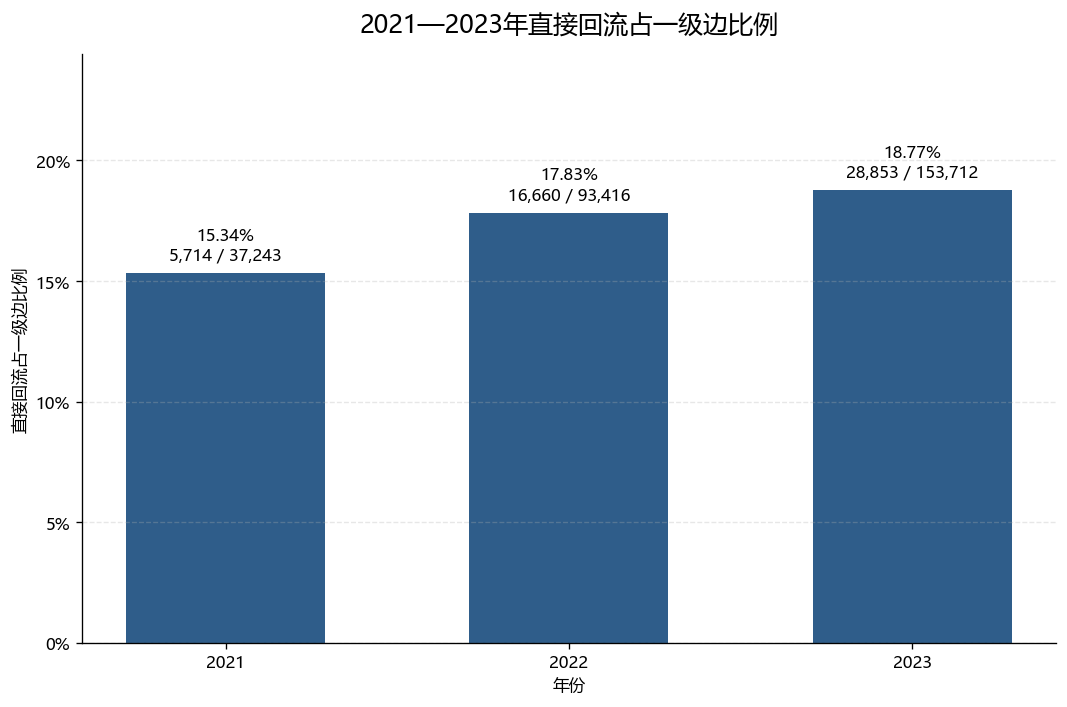

In [11]:
return_chart_data = return_summary.sort_values('year').copy()

fig, axis = plt.subplots(figsize=(9, 6))
bars = axis.bar(
    return_chart_data['year'].astype(str),
    return_chart_data['return_share'],
    color='#2F5D8A',
    width=0.58,
)

axis.set_title('2021—2023年直接回流占一级边比例', fontsize=15, pad=14)
axis.set_xlabel('年份')
axis.set_ylabel('直接回流占一级边比例')
axis.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f'{value:.0%}'))
axis.set_ylim(0, return_chart_data['return_share'].max() * 1.30)
axis.grid(axis='y', linestyle='--', alpha=0.30)
axis.spines['top'].set_visible(False)
axis.spines['right'].set_visible(False)

for bar, row in zip(bars, return_chart_data.itertuples(index=False)):
    axis.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.004,
        f'{row.return_share:.2%}\n{int(row.return_event_count):,} / {int(row.direct_edge_count):,}',
        ha='center',
        va='bottom',
        fontsize=10,
    )

fig.tight_layout()
fig.savefig(return_share_chart_file, dpi=200, bbox_inches='tight')
plt.show()

### 回流路径数据

`回流路径.csv`一行代表一次直接回流。`回流路径`从最近一次到达同一城市开始，到本次返回该城市结束。例如 `C-D-C`。如果同一台农机之后又再次返回C，会另记一行。

`同年同路径出现次数`按年份和完整城市字符串统计；`三年同路径出现次数`把三年合在一起统计。它们只是重复出现次数，不表示因果关系或稳定迁移概率。

In [12]:
display(Markdown(f'回流路径数据共 **{len(return_output):,}** 行。下面只显示前10行。'))
display(return_output.head(10))

回流路径数据共 **51,227** 行。下面只显示前10行。

,回流记录编号,年份,农机编号,链段编号,本机年度回流序次,上次到达该城访问序号,本次返回该城访问序号,回流城市,回流前城市,回流路径,...,本次返回进入时间,本次返回离开时间,离开后返回间隔小时,回流城市访问序次,是否时间冲突,回流城市是否81城,回流前城市是否81城,同年同路径出现次数,三年同路径出现次数,来源文件
0,2021-370150950-1-R001,2021,370150950,1,1,1,4,盐城市,南通市,盐城市→宣城市→南通市→盐城市,...,2021-06-05 06:53:44,2021-06-25 05:35:03,424.514444,2,False,True,True,1,1,Data/00_原始数据_只读/final_filtered_21_modified.csv
1,2021-370150963-1-R001,2021,370150963,1,1,4,6,泰州市,扬州市,泰州市→扬州市→泰州市,...,2021-05-30 13:42:28,2021-05-30 17:54:27,19.892222,2,False,True,True,30,166,Data/00_原始数据_只读/final_filtered_21_modified.csv
2,2021-370150963-1-R002,2021,370150963,1,2,5,7,扬州市,泰州市,扬州市→泰州市→扬州市,...,2021-05-31 05:57:16,2021-05-31 08:24:19,18.057500,2,False,True,True,32,176,Data/00_原始数据_只读/final_filtered_21_modified.csv
3,2021-370150963-1-R003,2021,370150963,1,3,6,8,泰州市,扬州市,泰州市→扬州市→泰州市,...,2021-05-31 14:11:06,2021-05-31 15:40:02,20.277500,3,False,True,True,30,166,Data/00_原始数据_只读/final_filtered_21_modified.csv
4,2021-370150963-1-R004,2021,370150963,1,4,7,9,扬州市,泰州市,扬州市→泰州市→扬州市,...,2021-05-31 17:22:54,2021-05-31 17:42:10,8.976389,3,False,True,True,32,176,Data/00_原始数据_只读/final_filtered_21_modified.csv
5,2021-370150963-1-R005,2021,370150963,1,5,8,10,泰州市,扬州市,泰州市→扬州市→泰州市,...,2021-05-31 20:22:00,2021-06-02 17:18:17,4.699444,4,False,True,True,30,166,Data/00_原始数据_只读/final_filtered_21_modified.csv
6,2021-370150963-1-R006,2021,370150963,1,6,9,11,扬州市,泰州市,扬州市→泰州市→扬州市,...,2021-06-03 07:41:01,2021-06-04 16:31:48,61.980833,4,False,True,True,32,176,Data/00_原始数据_只读/final_filtered_21_modified.csv
7,2021-370150963-1-R007,2021,370150963,1,7,10,12,泰州市,扬州市,泰州市→扬州市→泰州市,...,2021-06-05 07:20:59,2021-06-09 14:07:26,62.045000,5,False,True,True,30,166,Data/00_原始数据_只读/final_filtered_21_modified.csv
8,2021-370150963-1-R008,2021,370150963,1,8,1,13,连云港市,泰州市,连云港市→无锡市→常州市→泰州市→扬州市→泰州市→扬州市→泰州市→扬州市→泰州市→扬州市→泰...,...,2021-06-10 17:01:40,2021-06-22 14:25:19,509.705278,2,False,True,True,1,1,Data/00_原始数据_只读/final_filtered_21_modified.csv
9,2021-370150973-1-R001,2021,370150973,1,1,6,8,连云港市,临沂市,连云港市→临沂市→连云港市,...,2021-06-13 09:59:08,2021-06-14 06:36:16,110.859167,2,False,True,True,20,238,Data/00_原始数据_只读/final_filtered_21_modified.csv


In [13]:
def calculate_sha256(file_path):
    digest = hashlib.sha256()
    with open(file_path, 'rb') as file_handle:
        for file_chunk in iter(lambda: file_handle.read(1024 * 1024), b''):
            digest.update(file_chunk)
    return digest.hexdigest()


output_check_rows = []
for output_path in output_files:
    if not output_path.exists() or output_path.stat().st_size == 0:
        raise FileNotFoundError(f'输出不存在或为空：{output_path}')
    output_check_rows.append({
        '文件': str(output_path.relative_to(project_root)),
        '文件大小（字节）': output_path.stat().st_size,
        'SHA-256': calculate_sha256(output_path),
    })

saved_weight_table = pd.read_csv(weight_table_file, encoding='utf-8-sig')
saved_city_scope_table = pd.read_csv(city_scope_table_file, encoding='utf-8-sig')
saved_return_paths = pd.read_csv(return_path_file, encoding='utf-8-sig')
assert len(saved_weight_table) == len(weight_output), '边权重统计保存后行数改变。'
assert len(saved_city_scope_table) == len(city_scope_output), '81城边范围统计保存后行数改变。'
assert len(saved_return_paths) == len(return_output), '回流路径保存后行数改变。'

display(pd.DataFrame(output_check_rows))
display(Markdown('所有输出均已生成并重新读回检查。'))
for path,table in [(weight_table_file,weight_output),(city_scope_table_file,city_scope_output),(return_path_file,return_output)]:
    mask=manifest_table['relative_path'].eq(path.relative_to(project_root).as_posix())
    assert mask.sum()==1
    manifest_table.loc[mask,'row_count']=str(len(table))
    manifest_table.loc[mask,'file_size_bytes']=str(path.stat().st_size)
    manifest_table.loc[mask,'sha256']=calculate_sha256(path)
    manifest_table.loc[mask,'notes']='2026-10-21按人工删除后第一步候选接续重跑；统计范围与原定义不变'
manifest_table.to_csv(manifest_path,index=False,encoding='utf-8-sig')


,文件,文件大小（字节）,SHA-256
0,Results\00_数据审计\边权重统计.csv,3884,f126674890293971d88673a4df151338d107689e258b73...
1,Results\00_数据审计\81城边范围统计.csv,521,1759955652e2ce6dc634f10c49aade400babb238efd49d...
2,Data\03_有向边数据\回流路径.csv,15352459,36dcc5d375b0825fbe72a7a018d20978734d21a6678f6a...
3,Results\00_数据审计\边权重数量.png,166638,99afeeed406e702ea389501407acd2ece476626fe39624...
4,Results\00_数据审计\81城边范围.png,95820,714a962acb26af9c4e1042f250d02fdf5a50dfb8c8f0a3...
5,Results\00_数据审计\直接回流占比.png,78980,fb6e354c294cdd53f5caa3ea696c8389e5de4a41fcaa66...


所有输出均已生成并重新读回检查。